# BiasSpectr Nanonis 33 Samples

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from os.path import join

from prisma.file import load_np_val
from prisma.physics_models.jax import beem_integral_f_vector_j
from prisma.plot import plot_hist_series, plot_spectrum_series, \
    plot_spectrum_series_fit, set_rc_journal_const_wh

In [3]:
base_dir = r"C:\Users\djbasil\Documents\Data\BEEM_Data"
data_dir = join(base_dir, "Nanonis_Measure_ct_100_p_33_2")
figure_dir = join(base_dir, "Figure_Data")

In [4]:
set_rc_journal_const_wh()

# Samples

In [5]:
spectrum_series = load_np_val(data_dir, 'spectr_bias_series.npy')

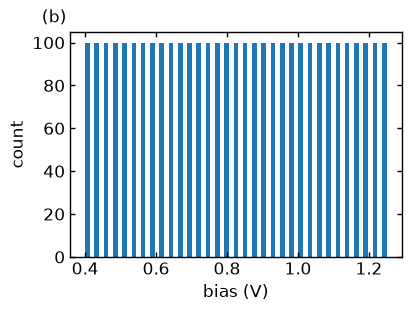

In [6]:
plot_hist_series(spectrum_series.flatten(), bins=65,
                 xlabel="bias (V)",
                #  title="Sample Locations",
                 id="(b)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_33_samples.pdf"))

# Spectrum

In [7]:
t_series = load_np_val(data_dir, 'spectr_current_series.npy')

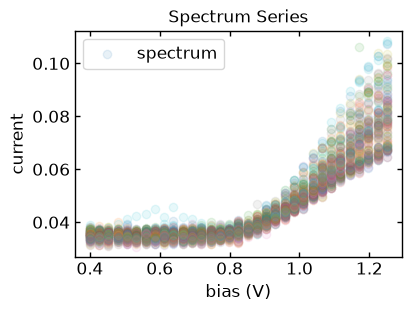

In [8]:
plot_spectrum_series(spectrum_series, -1 * t_series, xlabel="bias (V)", ylabel="current", title="Spectrum Series")

# Barrier

In [9]:
w_opt_series = load_np_val(data_dir, 'w_opt_series_Ibeem.npy')

In [10]:
barrier_fit = w_opt_series[:, 1]

In [11]:
barrier_fit

array([0.8656006 , 0.86173517, 0.8584708 , 0.85650365, 0.84360386,
       0.84338874, 0.84966252, 0.83840192, 0.86672362, 0.86873758,
       0.87105167, 0.86931943, 0.84826773, 0.86953963, 0.82850084,
       0.84751463, 0.85208853, 0.83589042, 0.86301417, 0.87198258,
       0.8591799 , 0.85241121, 0.84506204, 0.84971135, 0.84793246,
       0.84295671, 0.86851266, 0.840244  , 0.85175746, 0.85293437,
       0.85672821, 0.79989647, 0.88192075, 0.93147067, 0.85342425,
       0.8792526 , 0.86708963, 0.85805496, 0.87156269, 0.87606668,
       0.87430322, 0.90159155, 0.8989462 , 0.93527125, 0.91881847,
       0.92559562, 0.89624487, 0.91278535, 0.86411177, 0.90949092,
       0.87485013, 0.88262325, 0.90504163, 0.88393805, 0.90915978,
       0.8747859 , 0.89573512, 0.88931544, 0.90974229, 0.89855635,
       0.90172579, 0.90372091, 0.91212535, 0.88809661, 0.88614064,
       0.8553304 , 0.91014988, 0.8983935 , 0.90190694, 0.91494235,
       0.89924608, 0.87011905, 0.87215413, 0.88504659, 0.86471

In [12]:
np.mean(barrier_fit)

np.float64(0.8739922732173588)

In [13]:
np.std(barrier_fit)

np.float64(0.025090668359474298)

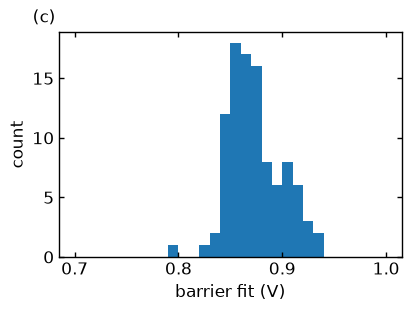

In [14]:
plot_hist_series(barrier_fit, bins=30, range=(.7, 1.),
                 xlabel="barrier fit (V)",
                #  title="Barrier Fit",
                 id="(c)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_33_barrier.pdf"))

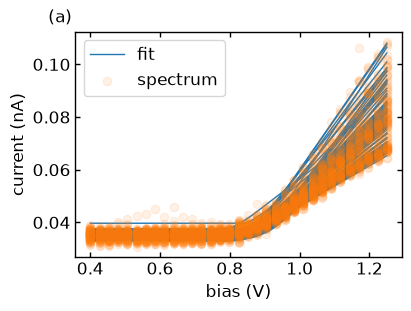

In [15]:
plot_spectrum_series_fit(spectrum_series, -1 * t_series,
                         np.linspace(np.min(spectrum_series),
                                     np.max(spectrum_series),
                                     100),
                         w_opt_series,
                         beem_integral_f_vector_j,
                         xlabel="bias (V)",
                         ylabel="current (nA)",
                         #  title="I/V Spectra",
                         f_save=join(figure_dir, "BiasSpectr_nanonis_33_spectrum_fit.pdf"),
                         id="(a)",
                         color_fit='C0', color_series='C1')

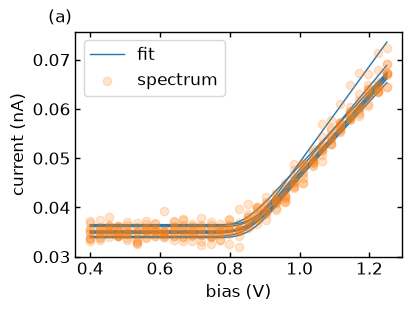

In [16]:
subset_lim = 10
plot_spectrum_series_fit(spectrum_series[:subset_lim], -1 * t_series[:subset_lim],
                         np.linspace(np.min(spectrum_series),
                                     np.max(spectrum_series),
                                     100),
                         w_opt_series[:subset_lim],
                         beem_integral_f_vector_j,
                         xlabel="bias (V)",
                         ylabel="current (nA)",
                         #  title="I/V Spectra",
                         f_save=join(figure_dir, "BiasSpectr_nanonis_33_spectrum_fit_subset.pdf"),
                         id="(a)",
                         color_fit='C0', color_series='C1', alpha=.2)

# Confidence

In [17]:
w_cov_series = load_np_val(data_dir, 'w_cov_Ibeem_series_Ibeem.npy')

In [18]:
barrier_stddev = np.sqrt(w_cov_series[:, 1, 1])

In [19]:
barrier_stddev

array([0.00816254, 0.00819004, 0.00668094, 0.00939207, 0.00768494,
       0.0077249 , 0.01094284, 0.00956023, 0.00857126, 0.00870283,
       0.01224017, 0.0089379 , 0.00944525, 0.00693826, 0.009049  ,
       0.00869318, 0.00740864, 0.0071211 , 0.00951612, 0.00893957,
       0.00861662, 0.00735754, 0.00631373, 0.00712695, 0.01171961,
       0.0082428 , 0.00824804, 0.00702961, 0.00900322, 0.00810478,
       0.00933085, 0.02983131, 0.00673217, 0.0093937 , 0.00836194,
       0.00623813, 0.00459961, 0.00686281, 0.00775261, 0.00492312,
       0.00486952, 0.00764524, 0.0253639 , 0.00837142, 0.00870325,
       0.0077018 , 0.01144644, 0.01227987, 0.01211786, 0.00660904,
       0.00756092, 0.00980407, 0.00976891, 0.00794428, 0.00959438,
       0.00790956, 0.01077817, 0.0071598 , 0.00742256, 0.00734479,
       0.00648802, 0.00678564, 0.00633538, 0.0083834 , 0.00709479,
       0.01250815, 0.00657924, 0.00679812, 0.00824914, 0.01002406,
       0.01135225, 0.00568845, 0.00769122, 0.0092949 , 0.00783

In [20]:
np.mean(barrier_stddev)

np.float64(0.008494307274482811)

In [21]:
np.std(barrier_stddev)

np.float64(0.003303609985569919)

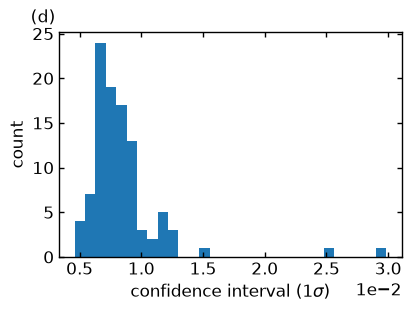

In [22]:
plot_hist_series(barrier_stddev, bins=30,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier Confidence",
                 id="(d)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_33_barrier_stddev.pdf"))

# Threshold

In [23]:
w_opt_series[:, 2]

array([8.05689016e-06, 8.18895656e-06, 8.23718454e-06, 8.43892967e-06,
       7.68020902e-06, 7.76659116e-06, 7.89616515e-06, 7.56715765e-06,
       9.77277288e-06, 8.48609370e-06, 9.00689691e-06, 8.75455224e-06,
       8.39004493e-06, 8.73219167e-06, 7.82712837e-06, 8.11405733e-06,
       8.15027769e-06, 8.08872780e-06, 8.38414371e-06, 8.57445047e-06,
       8.39595872e-06, 8.18920311e-06, 8.26453893e-06, 8.10461293e-06,
       8.09499160e-06, 7.89762270e-06, 8.45610439e-06, 7.88855287e-06,
       8.02855017e-06, 8.20423528e-06, 8.18401981e-06, 1.01645131e-05,
       1.67210683e-05, 1.79416019e-05, 1.37162930e-05, 1.66923551e-05,
       1.59426778e-05, 1.65981189e-05, 1.80170319e-05, 1.92303240e-05,
       1.89987372e-05, 1.33143230e-05, 1.63495557e-05, 1.52423200e-05,
       1.49090786e-05, 1.24700255e-05, 1.03882575e-05, 1.10598490e-05,
       1.10369134e-05, 2.05987663e-05, 1.28709585e-05, 1.06906111e-05,
       1.41446531e-05, 1.14934807e-05, 1.36008617e-05, 1.15338845e-05,
      

In [24]:
# thresh_series = w_opt_series[:, 2] < 1.4e-5
thresh_series = (w_opt_series[:, 1] > .8) & (w_opt_series[:, 1] < .89)

In [25]:
np.sum(thresh_series)

np.int64(74)

In [26]:
spectrum_series_thresh = spectrum_series[thresh_series]

In [27]:
t_series_thresh = t_series[thresh_series]

# Spectrum

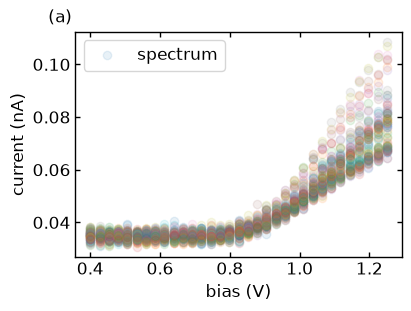

In [28]:
plot_spectrum_series(spectrum_series_thresh, -1 * t_series_thresh,
                     xlabel="bias (V)",
                     ylabel="current (nA)",
                    #  title="I/V Spectra",
                     id="(a)",
                     f_save=join(figure_dir, "BiasSpectr_nanonis_33_spectrum_rmout.pdf"))

# Samples

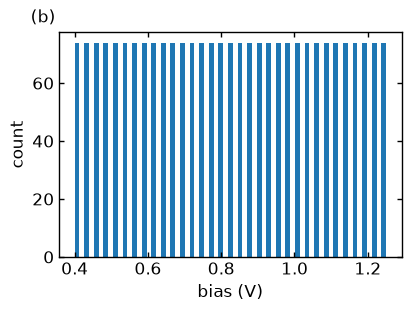

In [29]:
plot_hist_series(spectrum_series_thresh.flatten(), bins=65,
                 xlabel="bias (V)",
                #  title="Sample Locations",
                 id="(b)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_33_samples_rmout.pdf"))

# Barrier

In [30]:
w_opt_series_thresh = w_opt_series[thresh_series]

In [31]:
barrier_fit_thresh = w_opt_series_thresh[:, 1]

In [32]:
np.mean(barrier_fit_thresh)

np.float64(0.8629437006584603)

In [33]:
np.std(barrier_fit_thresh)

np.float64(0.013652936811210577)

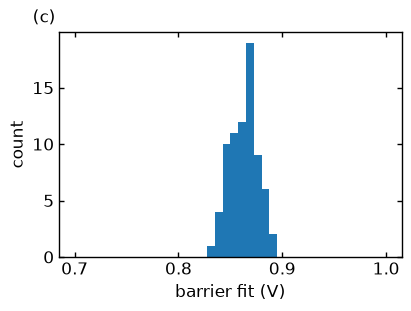

In [34]:
plot_hist_series(barrier_fit_thresh, bins=40, range=(.7, 1.),
                 xlabel="barrier fit (V)",
                #  title="Barrier Fit",
                 id="(c)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_33_barrier_rmout.pdf"))

# Spectrum Fit

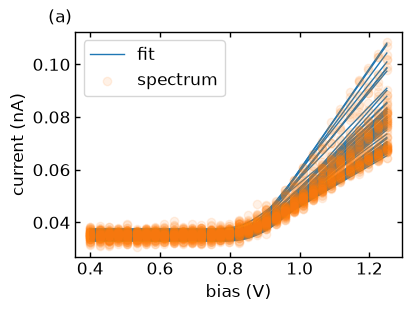

In [35]:
plot_spectrum_series_fit(spectrum_series_thresh, -1 * t_series_thresh,
                         np.linspace(np.min(spectrum_series_thresh),
                                     np.max(spectrum_series_thresh),
                                     100),
                         w_opt_series_thresh,
                         beem_integral_f_vector_j,
                         xlabel="bias (V)",
                         ylabel="current (nA)",
                         #  title="I/V Spectra",
                         f_save=join(figure_dir, "BiasSpectr_nanonis_33_spectrum_fit_rmout.pdf"),
                         id="(a)",
                         color_fit='C0', color_series='C1')

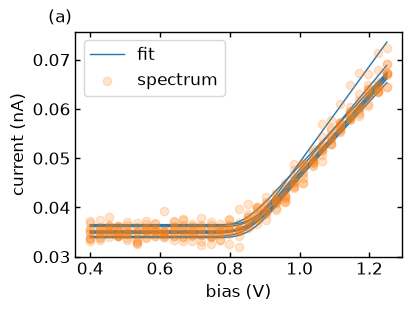

In [36]:
subset_lim = 10
plot_spectrum_series_fit(spectrum_series_thresh[:subset_lim], -1 * t_series_thresh[:subset_lim],
                         np.linspace(np.min(spectrum_series_thresh),
                                     np.max(spectrum_series_thresh),
                                     100),
                         w_opt_series_thresh[:subset_lim],
                         beem_integral_f_vector_j,
                         xlabel="bias (V)",
                         ylabel="current (nA)",
                         #  title="I/V Spectra",
                         f_save=join(figure_dir, "BiasSpectr_nanonis_33_spectrum_fit_rmout_subset.pdf"),
                         id="(a)",
                         color_fit='C0', color_series='C1', alpha=.2)

# Confidence

In [37]:
w_cov_series_thresh = w_cov_series[thresh_series]

In [38]:
barrier_stddev_thresh = np.sqrt(w_cov_series_thresh[:, 1, 1])

In [39]:
np.mean(barrier_stddev_thresh)

np.float64(0.007828705916640177)

In [40]:
np.std(barrier_stddev_thresh)

np.float64(0.001615500243119655)

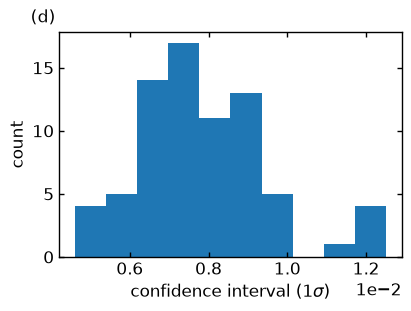

In [41]:
plot_hist_series(barrier_stddev_thresh, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier Confidence",
                 id="(d)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_33_barrier_stddev_rmout.pdf"))